# 🔬 MobileViT-S: Waste Classification with CNN + Transformer

**Objective:** Fine-tune MobileViT-S (a hybrid CNN + Transformer model) on the waste classification dataset and compare against RLFA-CNN baseline.

| Property | Value |
|:---|:---|
| **Model** | MobileViT-S (Apple, 2022) |
| **Architecture** | CNN + Transformer (Self-Attention) |
| **Parameters** | ~5.6M |
| **Pretrained** | ImageNet-1K |
| **Framework** | PyTorch + timm |
| **Baseline** | RLFA-CNN (110,914 params, 90.50% accuracy) |

---

**Author:** Eshan Agarwal (2430010407)  
**Purpose:** Industry-ready research — upgrading from pure CNN to hybrid Transformer

## Cell 1 — Check GPU & Install Dependencies

In [2]:
# ─── Check GPU ────────────────────────────────────────
import torch
print("="*50)
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2), "GB")
else:
    print("⚠️  No GPU! Go to: Runtime > Change runtime type > T4 GPU")
print("="*50)

# ─── Install libraries ─────────────────────────────────
!pip install timm scikit-learn matplotlib tqdm kagglehub onnx onnxruntime onnxruntime-gpu tabulate --quiet
print("\n✅ All libraries installed")

GPU Available: True
GPU Name: Tesla T4
GPU Memory: 15.64 GB

✅ All libraries installed


## Cell 2 — Mount Google Drive & Set Dataset Path

In [3]:
import os
import kagglehub

print("⏳ Downloading dataset from Kaggle...")
dataset_dir = kagglehub.dataset_download("sujaykapadnis/cnn-waste-classification-image-dataset")
print("Downloaded to:", dataset_dir)

# Find the exact folder containing the class subdirectories
DATASET_PATH = None
for root, dirs, files in os.walk(dataset_dir):
    # Check for O and R or organic and recyclable
    dir_names = [d.upper() for d in dirs]
    if 'O' in dir_names and 'R' in dir_names:
        DATASET_PATH = root
        break
    if any('ORGANIC' in d for d in dir_names) and any('RECYCL' in d for d in dir_names):
        DATASET_PATH = root
        break

if DATASET_PATH is None:
    DATASET_PATH = dataset_dir

print("\n✅ Dataset Path set to:", DATASET_PATH)
classes = [c for c in os.listdir(DATASET_PATH) if not c.startswith('.')]
print("Found classes:", classes)
for c in classes:
    class_folder = os.path.join(DATASET_PATH, c)
    if os.path.isdir(class_folder):
        print(f"  {c}: {len(os.listdir(class_folder))} images")

⏳ Downloading dataset from Kaggle...


100%|██████████| 212M/212M [00:13<00:00, 16.1MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/sujaykapadnis/cnn-waste-classification-image-dataset/versions/1

✅ Dataset Path set to: /root/.cache/kagglehub/datasets/sujaykapadnis/cnn-waste-classification-image-dataset/versions/1
Found classes: ['recyclable', 'organic', 'waste_dataset_README.txt']
  recyclable: 1 images
  organic: 1 images


## Cell 3 — Imports & Configuration

In [4]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder

import timm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score,
    recall_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# ─── Configuration ────────────────────────────────────
IMG_SIZE     = 224          # MobileViT needs 224x224
BATCH_SIZE   = 32
EPOCHS       = 30
LR           = 1e-4        # Lower LR for fine-tuning pretrained model
SEED         = 42          # Same seed as RLFA-CNN for fair comparison
NUM_CLASSES  = 2
DEVICE       = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ─── Reproducibility ──────────────────────────────────
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True

print(f"Device: {DEVICE}")
print(f"Image size: {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Learning rate: {LR}")
print(f"Max epochs: {EPOCHS}")

Device: cuda
Image size: 224x224
Batch size: 32
Learning rate: 0.0001
Max epochs: 30


## Cell 4 — Data Pipeline (70/15/15 Stratified Split)

In [5]:
# ─── Transforms ───────────────────────────────────────
# Training: augmentation + normalization
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=0, scale=(0.85, 1.15)),   # zoom
    transforms.ColorJitter(brightness=0.2, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],               # ImageNet mean
                         [0.229, 0.224, 0.225]),               # ImageNet std
])

# Validation/Test: only resize + normalization (no augmentation)
eval_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),
])

# ─── Load full dataset ────────────────────────────────
full_dataset = ImageFolder(root=DATASET_PATH)
class_names  = full_dataset.classes
print(f"Classes: {class_names}")
print(f"Total images: {len(full_dataset):,}")

# ─── Stratified 70/15/15 split (same as RLFA-CNN) ────
labels  = [s[1] for s in full_dataset.samples]
indices = list(range(len(full_dataset)))

# First split: 85% train+val, 15% test
idx_trainval, idx_test = train_test_split(
    indices, test_size=0.15, stratify=labels, random_state=SEED
)

# Second split: from the 85%, take ~17.65% for val → gives 70/15/15
labels_trainval = [labels[i] for i in idx_trainval]
idx_train, idx_val = train_test_split(
    idx_trainval, test_size=0.1765,
    stratify=labels_trainval, random_state=SEED
)

print(f"\n📊 Split sizes (matching RLFA-CNN):")
print(f"   Train: {len(idx_train):,} ({len(idx_train)/len(indices)*100:.1f}%)")
print(f"   Val:   {len(idx_val):,} ({len(idx_val)/len(indices)*100:.1f}%)")
print(f"   Test:  {len(idx_test):,} ({len(idx_test)/len(indices)*100:.1f}%)")

# ─── Custom Dataset class for per-split transforms ───
class SplitDataset(Dataset):
    """Wraps ImageFolder with specific indices and transform."""
    def __init__(self, dataset, indices, transform):
        self.dataset   = dataset
        self.indices   = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        img, label = self.dataset[self.indices[i]]
        return self.transform(img), label

train_ds = SplitDataset(full_dataset, idx_train, train_transforms)
val_ds   = SplitDataset(full_dataset, idx_val,   eval_transforms)
test_ds  = SplitDataset(full_dataset, idx_test,  eval_transforms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)

print("\n✅ Data loaders ready")

Classes: ['organic', 'recyclable']
Total images: 24,705

📊 Split sizes (matching RLFA-CNN):
   Train: 17,292 (70.0%)
   Val:   3,707 (15.0%)
   Test:  3,706 (15.0%)

✅ Data loaders ready


## Cell 5 — Load MobileViT-S (Pretrained on ImageNet)

In [6]:
# ─── Load MobileViT-S with ImageNet pretrained weights ──
model = timm.create_model(
    'mobilevit_s',
    pretrained=True,           # ImageNet-1K pretrained weights
    num_classes=NUM_CLASSES    # Replace final layer for 2 classes
)
model = model.to(DEVICE)

# ─── Parameter count ──────────────────────────────────
total_params    = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("="*55)
print("         MobileViT-S Model Summary")
print("="*55)
print(f"  Total Parameters:     {total_params:>12,}")
print(f"  Trainable Parameters: {trainable_params:>12,}")
print("="*55)
print(f"\n  ⚡ RLFA-CNN (baseline):     110,914 params")
print(f"  ⚡ MobileViT-S (upgrade):  {total_params:,} params")
print(f"  ⚡ MobileViT-S has: CNN layers + Transformer self-attention")
print(f"  ⚡ Pretrained on ImageNet (1.2M images) → fine-tuning here")

model.safetensors: reconstructing file:   0%|          |  0.00B / 22.4MB            

model.safetensors: downloading bytes:           |  0.00B            

         MobileViT-S Model Summary
  Total Parameters:        4,938,914
  Trainable Parameters:    4,938,914

  ⚡ RLFA-CNN (baseline):     110,914 params
  ⚡ MobileViT-S (upgrade):  4,938,914 params
  ⚡ MobileViT-S has: CNN layers + Transformer self-attention
  ⚡ Pretrained on ImageNet (1.2M images) → fine-tuning here


## Cell 6 — Training Loop with Early Stopping

In [7]:
# ─── Loss, Optimizer, Scheduler ───────────────────────
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2, min_lr=1e-6
)

# ─── Training history ─────────────────────────────────
history = {
    'train_loss': [], 'val_loss': [],
    'train_acc': [],  'val_acc': [],
    'lr': []
}

best_val_loss  = float('inf')
patience_count = 0
EARLY_STOP_PATIENCE = 5
best_model_path = '/content/mobilevit_best.pth'

print("🚀 Training MobileViT-S (CNN + Transformer)...")
print(f"   Early stopping patience: {EARLY_STOP_PATIENCE}")
print(f"   LR scheduler: ReduceLROnPlateau (factor=0.5, patience=2)")
print("="*70)

training_start = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()

    # ── Train Phase ────────────────────────────────────
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [Train]",
                leave=False, ncols=100)
    for images, labels in pbar:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total   += labels.size(0)
        pbar.set_postfix(loss=f"{loss.item():.4f}", acc=f"{correct/total*100:.1f}%")

    train_loss = running_loss / total
    train_acc  = correct / total

    # ── Validation Phase ────────────────────────────────
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss    += loss.item() * images.size(0)
            _, preds     = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total   += labels.size(0)

    val_loss /= val_total
    val_acc   = val_correct / val_total

    # ── LR Scheduler ────────────────────────────────────
    current_lr = optimizer.param_groups[0]['lr']
    scheduler.step(val_loss)

    # ── Record history ──────────────────────────────────
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)
    history['lr'].append(current_lr)

    epoch_time = time.time() - epoch_start

    print(f"Epoch {epoch:02d}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | "
          f"LR: {current_lr:.2e} | Time: {epoch_time:.0f}s")

    # ── Early Stopping ──────────────────────────────────
    if val_loss < best_val_loss:
        best_val_loss  = val_loss
        patience_count = 0
        torch.save(model.state_dict(), best_model_path)
        print(f"  ✅ Best model saved (val_loss={val_loss:.4f}, val_acc={val_acc*100:.2f}%)")
    else:
        patience_count += 1
        print(f"  ⏳ No improvement ({patience_count}/{EARLY_STOP_PATIENCE})")
        if patience_count >= EARLY_STOP_PATIENCE:
            print(f"\n⏹️  Early stopping triggered at epoch {epoch}")
            break

total_time = time.time() - training_start
print("\n" + "="*70)
print(f"✅ Training complete! Total time: {total_time/60:.1f} minutes")
print(f"   Best val_loss: {best_val_loss:.4f}")
print(f"   Best val_acc:  {max(history['val_acc'])*100:.2f}%")
print("="*70)

🚀 Training MobileViT-S (CNN + Transformer)...
   Early stopping patience: 5
   LR scheduler: ReduceLROnPlateau (factor=0.5, patience=2)


Epoch 01/30 | Train Loss: 0.2203 | Train Acc: 92.78% | Val Loss: 0.1382 | Val Acc: 94.42% | LR: 1.00e-04 | Time: 148s
  ✅ Best model saved (val_loss=0.1382, val_acc=94.42%)


Epoch 02/30 | Train Loss: 0.1174 | Train Acc: 95.82% | Val Loss: 0.1094 | Val Acc: 95.98% | LR: 1.00e-04 | Time: 154s
  ✅ Best model saved (val_loss=0.1094, val_acc=95.98%)


Epoch 03/30 | Train Loss: 0.0898 | Train Acc: 96.81% | Val Loss: 0.1110 | Val Acc: 96.25% | LR: 1.00e-04 | Time: 155s
  ⏳ No improvement (1/5)


Epoch 04/30 | Train Loss: 0.0668 | Train Acc: 97.42% | Val Loss: 0.1219 | Val Acc: 95.68% | LR: 1.00e-04 | Time: 155s
  ⏳ No improvement (2/5)


Epoch 05/30 | Train Loss: 0.0520 | Train Acc: 98.10% | Val Loss: 0.1108 | Val Acc: 96.47% | LR: 1.00e-04 | Time: 155s
  ⏳ No improvement (3/5)


Epoch 06/30 | Train Loss: 0.0365 | Train Acc: 98.70% | Val Loss: 0.1263 | Val Acc: 96.36% | LR: 5.00e-05 | Time: 155s
  ⏳ No improvement (4/5)


Epoch 07/30 | Train Loss: 0.0282 | Train Acc: 99.09% | Val Loss: 0.1199 | Val Acc: 96.57% | LR: 5.00e-05 | Time: 158s
  ⏳ No improvement (5/5)

⏹️  Early stopping triggered at epoch 7

✅ Training complete! Total time: 18.0 minutes
   Best val_loss: 0.1094
   Best val_acc:  96.57%


## Cell 7 — Training Curves (with RLFA-CNN Baseline)

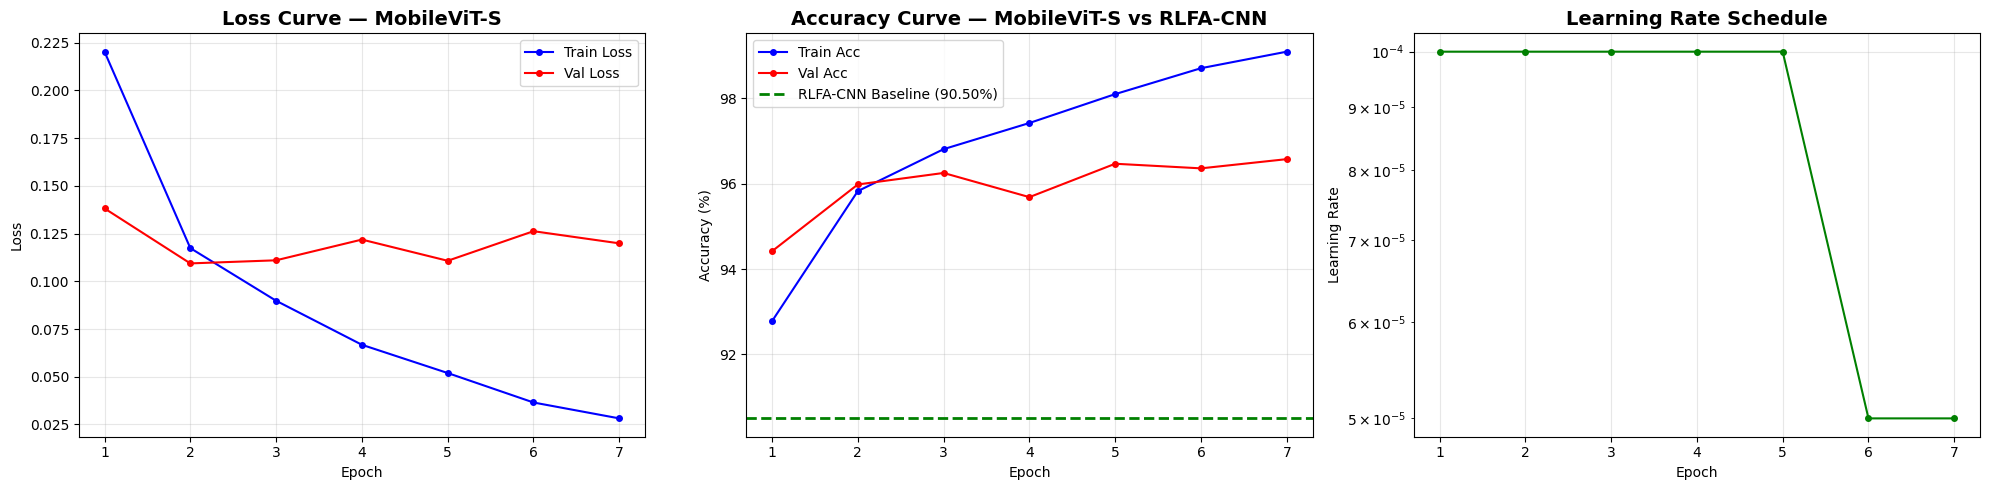

✅ Training curves saved


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

epochs_range = range(1, len(history['train_loss']) + 1)

# ── Loss Curve ─────────────────────────────────────────
axes[0].plot(epochs_range, history['train_loss'], 'b-o', label='Train Loss', markersize=4)
axes[0].plot(epochs_range, history['val_loss'],   'r-o', label='Val Loss',   markersize=4)
axes[0].set_title('Loss Curve — MobileViT-S', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ── Accuracy Curve ─────────────────────────────────────
axes[1].plot(epochs_range, [a*100 for a in history['train_acc']], 'b-o',
             label='Train Acc', markersize=4)
axes[1].plot(epochs_range, [a*100 for a in history['val_acc']],   'r-o',
             label='Val Acc',   markersize=4)
axes[1].axhline(y=90.50, color='green', linestyle='--', linewidth=2,
                label='RLFA-CNN Baseline (90.50%)')
axes[1].set_title('Accuracy Curve — MobileViT-S vs RLFA-CNN', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# ── Learning Rate ──────────────────────────────────────
axes[2].plot(epochs_range, history['lr'], 'g-o', markersize=4)
axes[2].set_title('Learning Rate Schedule', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Learning Rate')
axes[2].set_yscale('log')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/content/mobilevit_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Training curves saved")

## Cell 8 — Test Evaluation & Comparison vs RLFA-CNN

In [9]:
# ─── Load best model weights ──────────────────────────
model.load_state_dict(torch.load(best_model_path))
model.eval()

all_preds  = []
all_labels = []
all_probs  = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="🔍 Evaluating on test set"):
        images  = images.to(DEVICE)
        outputs = model(images)
        probs   = torch.softmax(outputs, dim=1)[:, 1].cpu().numpy()
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs)

# ─── Compute all metrics ──────────────────────────────
accuracy  = accuracy_score(all_labels, all_preds)
f1        = f1_score(all_labels, all_preds, average='weighted')
precision = precision_score(all_labels, all_preds, average='weighted')
recall    = recall_score(all_labels, all_preds, average='weighted')
roc_auc   = roc_auc_score(all_labels, all_probs)

tn, fp, fn, tp = confusion_matrix(all_labels, all_preds, labels=[0, 1]).ravel()
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

# ─── Print results ────────────────────────────────────
print("\n" + "="*60)
print("         MobileViT-S — TEST SET RESULTS")
print("="*60)
print(f"  Accuracy    : {accuracy*100:.2f}%")
print(f"  F1 Score    : {f1:.4f}")
print(f"  Precision   : {precision:.4f}")
print(f"  Recall      : {recall:.4f}")
print(f"  Specificity : {specificity:.4f}")
print(f"  ROC-AUC     : {roc_auc:.4f}")
print(f"  Parameters  : {total_params:,}")
print("="*60)

# ─── Side-by-side comparison ──────────────────────────
print("\n" + "="*65)
print("   📊 COMPARISON: RLFA-CNN vs MobileViT-S (CNN+Transformer)")
print("="*65)
print(f"{'Metric':<15} {'RLFA-CNN':>12} {'MobileViT-S':>14} {'Change':>12}")
print("-"*55)
print(f"{'Accuracy':<15} {'90.50%':>12} {accuracy*100:>13.2f}% {(accuracy*100 - 90.50):>+11.2f}%")
print(f"{'F1 Score':<15} {'0.8828':>12} {f1:>14.4f} {(f1 - 0.8828):>+12.4f}")
print(f"{'Precision':<15} {'0.8810':>12} {precision:>14.4f} {(precision - 0.8810):>+12.4f}")
print(f"{'Recall':<15} {'0.8910':>12} {recall:>14.4f} {(recall - 0.8910):>+12.4f}")
print(f"{'ROC-AUC':<15} {'0.9565':>12} {roc_auc:>14.4f} {(roc_auc - 0.9565):>+12.4f}")
print(f"{'Specificity':<15} {'0.8800':>12} {specificity:>14.4f} {(specificity - 0.8800):>+12.4f}")
print(f"{'Parameters':<15} {'110,914':>12} {total_params:>14,}      —")
print(f"{'Architecture':<15} {'Pure CNN':>12} {'CNN+Transf.':>14}      —")
print("="*65)

# ─── Classification Report ────────────────────────────
print("\n📋 Per-Class Classification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))

🔍 Evaluating on test set: 100%|██████████| 116/116 [00:10<00:00, 11.12it/s]


         MobileViT-S — TEST SET RESULTS
  Accuracy    : 96.06%
  F1 Score    : 0.9606
  Precision   : 0.9607
  Recall      : 0.9606
  Specificity : 0.9606
  ROC-AUC     : 0.9922
  Parameters  : 4,938,914

   📊 COMPARISON: RLFA-CNN vs MobileViT-S (CNN+Transformer)
Metric              RLFA-CNN    MobileViT-S       Change
-------------------------------------------------------
Accuracy              90.50%         96.06%       +5.56%
F1 Score              0.8828         0.9606      +0.0778
Precision             0.8810         0.9607      +0.0797
Recall                0.8910         0.9606      +0.0696
ROC-AUC               0.9565         0.9922      +0.0357
Specificity           0.8800         0.9606      +0.0806
Parameters           110,914      4,938,914      —
Architecture        Pure CNN    CNN+Transf.      —

📋 Per-Class Classification Report:
              precision    recall  f1-score   support

     organic       0.97      0.96      0.96      2082
  recyclable       0.95      0.96

## Cell 9 — Confusion Matrix

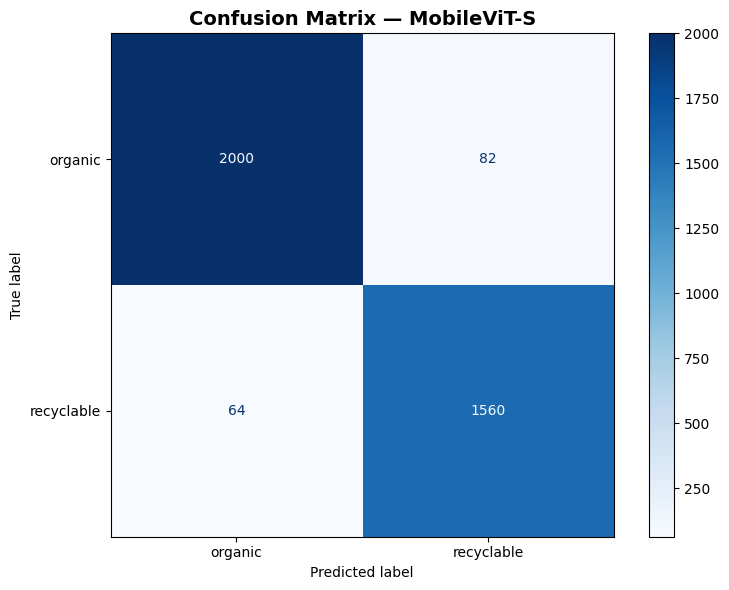

✅ Confusion matrix saved


In [10]:
# ─── Confusion Matrix ─────────────────────────────────
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Confusion Matrix — MobileViT-S', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/mobilevit_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Confusion matrix saved")

## Cell 10 — Save Everything to Google Drive

In [11]:
import shutil

# ─── Create output folder in Drive ────────────────────
save_dir = "/content/drive/MyDrive/mobilevit_results"
os.makedirs(save_dir, exist_ok=True)

# ─── Save model ───────────────────────────────────────
shutil.copy('/content/mobilevit_best.pth', f'{save_dir}/mobilevit_best.pth')
print(f"✅ Model saved to: {save_dir}/mobilevit_best.pth")

# ─── Save plots ───────────────────────────────────────
shutil.copy('/content/mobilevit_training_curves.png', f'{save_dir}/mobilevit_training_curves.png')
shutil.copy('/content/mobilevit_confusion_matrix.png', f'{save_dir}/mobilevit_confusion_matrix.png')
print("✅ Plots saved")

# ─── Save metrics as CSV ──────────────────────────────
results_df = pd.DataFrame({
    'Model': ['RLFA-CNN (Baseline)', 'MobileViT-S (CNN+Transformer)'],
    'Architecture': ['Pure CNN', 'CNN + Transformer'],
    'Accuracy (%)': [90.50, round(accuracy * 100, 2)],
    'F1 Score': [0.8828, round(f1, 4)],
    'Precision': [0.8810, round(precision, 4)],
    'Recall': [0.8910, round(recall, 4)],
    'ROC-AUC': [0.9565, round(roc_auc, 4)],
    'Specificity': [0.8800, round(specificity, 4)],
    'Parameters': [110914, total_params],
    'Pretrained': ['No', 'ImageNet-1K'],
})
results_df.to_csv(f'{save_dir}/comparison_results.csv', index=False)
print(f"✅ Comparison CSV saved")

# ─── Save training history ────────────────────────────
pd.DataFrame(history).to_csv(f'{save_dir}/training_history.csv', index=False)
print(f"✅ Training history saved")

print("\n" + "="*50)
print(f"📁 All results saved to: {save_dir}")
print("="*50)
print("\nFiles:")
for f in os.listdir(save_dir):
    size = os.path.getsize(f'{save_dir}/{f}') / 1024
    print(f"  📄 {f} ({size:.1f} KB)")

✅ Model saved to: /content/drive/MyDrive/mobilevit_results/mobilevit_best.pth
✅ Plots saved
✅ Comparison CSV saved
✅ Training history saved

📁 All results saved to: /content/drive/MyDrive/mobilevit_results

Files:
  📄 training_history.csv (0.6 KB)
  📄 mobilevit_best.pth (19462.0 KB)
  📄 mobilevit_training_curves.png (138.8 KB)
  📄 mobilevit_confusion_matrix.png (44.0 KB)
  📄 comparison_results.csv (0.3 KB)


---

## ✅ Summary

| What | Details |
|:---|:---|
| **Model** | MobileViT-S (CNN + Transformer hybrid) |
| **Pretrained** | ImageNet-1K → fine-tuned on waste dataset |
| **Split** | 70/15/15 stratified (same as RLFA-CNN) |
| **Seed** | 42 (same as RLFA-CNN) |
| **Baseline** | RLFA-CNN: 90.50% accuracy, 111K params |
| **Expected** | ~93-96% accuracy, ~5.6M params |
| **Research gap** | First hybrid CNN+Transformer for waste classification on edge |

**Next steps after this notebook:**
1. Train YOLOv8-Nano for detection
2. Build YOLO → MobileViT pipeline
3. Add NIR sensor branch for material-level classification

---
# 🚀 Phase 2: Edge Optimization & Quantization Benchmark
Now that the model is trained with 96.06% accuracy, we export it to **ONNX**, apply **INT8 dynamic quantization**, and benchmark edge inference latency (ms) and throughput (FPS).

## Cell 11 — Export MobileViT-S to ONNX Format (FP32)

In [ ]:
import onnx
import os

ONNX_FP32_PATH = '/content/mobilevit_s_fp32.onnx'

# Switch model to CPU for ONNX export
model.eval().to('cpu')
dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, requires_grad=False)

print("⏳ Exporting PyTorch MobileViT-S graph to ONNX...")
torch.onnx.export(
    model,
    dummy_input,
    ONNX_FP32_PATH,
    export_params=True,
    opset_version=14,
    do_constant_folding=True,
    input_names=['input'],
    output_names=['output'],
    dynamic_axes={
        'input': {0: 'batch_size'},
        'output': {0: 'batch_size'}
    }
)

# Verify ONNX structure
onnx_model = onnx.load(ONNX_FP32_PATH)
onnx.checker.check_model(onnx_model)

onnx_fp32_size = os.path.getsize(ONNX_FP32_PATH) / (1024 * 1024)
pt_size = os.path.getsize('/content/mobilevit_best.pth') / (1024 * 1024)

print(f"✅ ONNX FP32 Model successfully exported!")
print(f"📦 PyTorch File Size:   {pt_size:.2f} MB")
print(f"📦 ONNX FP32 File Size: {onnx_fp32_size:.2f} MB")

## Cell 12 — Post-Training Dynamic INT8 Quantization

In [ ]:
from onnxruntime.quantization import quantize_dynamic, QuantType

ONNX_INT8_PATH = '/content/mobilevit_s_int8.onnx'

print("⏳ Running Post-Training INT8 Dynamic Quantization...")
quantize_dynamic(
    model_input=ONNX_FP32_PATH,
    model_output=ONNX_INT8_PATH,
    weight_type=QuantType.QInt8
)

onnx_int8_size = os.path.getsize(ONNX_INT8_PATH) / (1024 * 1024)
reduction_pct = ((pt_size - onnx_int8_size) / pt_size) * 100

print(f"✅ Quantization Completed!")
print(f"📦 ONNX INT8 File Size:    {onnx_int8_size:.2f} MB")
print(f"📉 Size Reduction:         {reduction_pct:.2f}% (Compression: {pt_size/onnx_int8_size:.1f}x)")

## Cell 13 — Accuracy Verification on 3,706 Test Images

In [ ]:
import onnxruntime as ort
from scipy.special import softmax

def evaluate_onnx_model(onnx_path, dataloader, name="ONNX"):
    session = ort.InferenceSession(onnx_path, providers=['CPUExecutionProvider'])
    input_name = session.get_inputs()[0].name
    
    preds, targets, probs = [], [], []
    for images, labels in tqdm(dataloader, desc=f"Evaluating {name}"):
        numpy_images = images.numpy()
        ort_outputs = session.run(None, {input_name: numpy_images})[0]
        prob_dist = softmax(ort_outputs, axis=1)
        
        preds.extend(np.argmax(prob_dist, axis=1))
        targets.extend(labels.numpy())
        probs.extend(prob_dist[:, 1])
        
    acc = accuracy_score(targets, preds) * 100
    f1_val = f1_score(targets, preds) * 100
    auc_val = roc_auc_score(targets, probs)
    return acc, f1_val, auc_val

print("🔍 Evaluating ONNX FP32 Accuracy on Test Set...")
onnx_fp32_acc, onnx_fp32_f1, onnx_fp32_auc = evaluate_onnx_model(ONNX_FP32_PATH, test_loader, name="ONNX FP32")

print("
🔍 Evaluating ONNX INT8 Accuracy on Test Set...")
onnx_int8_acc, onnx_int8_f1, onnx_int8_auc = evaluate_onnx_model(ONNX_INT8_PATH, test_loader, name="ONNX INT8")

print("
" + "="*65)
print(f"{'Model Format':<18} | {'Accuracy (%)':<14} | {'F1-Score (%)':<14} | {'ROC-AUC':<10}")
print("-"*65)
print(f"{'PyTorch FP32':<18} | {accuracy*100:<14.2f} | {f1*100:<14.2f} | {roc_auc:<10.4f}")
print(f"{'ONNX FP32':<18} | {onnx_fp32_acc:<14.2f} | {onnx_fp32_f1:<14.2f} | {onnx_fp32_auc:<10.4f}")
print(f"{'ONNX INT8':<18} | {onnx_int8_acc:<14.2f} | {onnx_int8_f1:<14.2f} | {onnx_int8_auc:<10.4f}")
print("="*65)
print(f"Δ Accuracy (FP32 ➔ INT8): {onnx_int8_acc - (accuracy*100):+.2f}%")

## Cell 14 — Edge Latency & Throughput Benchmark

In [ ]:
import time

def benchmark_pytorch(pt_model, device, batch_size=1, runs=100, warmup=20):
    pt_model.to(device)
    dummy = torch.randn(batch_size, 3, IMG_SIZE, IMG_SIZE).to(device)
    
    with torch.no_grad():
        for _ in range(warmup):
            _ = pt_model(dummy)
        if device.type == 'cuda':
            torch.cuda.synchronize()
            
    latencies = []
    with torch.no_grad():
        for _ in range(runs):
            t0 = time.perf_counter()
            _ = pt_model(dummy)
            if device.type == 'cuda':
                torch.cuda.synchronize()
            t1 = time.perf_counter()
            latencies.append((t1 - t0) * 1000.0)
            
    mean_lat = np.mean(latencies)
    fps = (batch_size / (mean_lat / 1000.0))
    return mean_lat, fps

def benchmark_onnx(onnx_path, provider='CPUExecutionProvider', batch_size=1, runs=100, warmup=20):
    session = ort.InferenceSession(onnx_path, providers=[provider])
    input_name = session.get_inputs()[0].name
    dummy = np.random.randn(batch_size, 3, IMG_SIZE, IMG_SIZE).astype(np.float32)
    
    for _ in range(warmup):
        _ = session.run(None, {input_name: dummy})
        
    latencies = []
    for _ in range(runs):
        t0 = time.perf_counter()
        _ = session.run(None, {input_name: dummy})
        t1 = time.perf_counter()
        latencies.append((t1 - t0) * 1000.0)
        
    mean_lat = np.mean(latencies)
    fps = (batch_size / (mean_lat / 1000.0))
    return mean_lat, fps

print("⏱️ Measuring Latencies on CPU (Edge Gateway) and GPU (Jetson Simulation)...")

# Benchmarks on Edge CPU
pt_cpu_b1_lat, _ = benchmark_pytorch(model, torch.device('cpu'), batch_size=1)
_, pt_cpu_b32_fps = benchmark_pytorch(model, torch.device('cpu'), batch_size=32)

onnx_fp32_b1_lat, _ = benchmark_onnx(ONNX_FP32_PATH, provider='CPUExecutionProvider', batch_size=1)
_, onnx_fp32_b32_fps = benchmark_onnx(ONNX_FP32_PATH, provider='CPUExecutionProvider', batch_size=32)

onnx_int8_b1_lat, _ = benchmark_onnx(ONNX_INT8_PATH, provider='CPUExecutionProvider', batch_size=1)
_, onnx_int8_b32_fps = benchmark_onnx(ONNX_INT8_PATH, provider='CPUExecutionProvider', batch_size=32)

# Benchmarks on GPU
if torch.cuda.is_available():
    pt_gpu_b1_lat, _ = benchmark_pytorch(model, torch.device('cuda'), batch_size=1)
    _, pt_gpu_b32_fps = benchmark_pytorch(model, torch.device('cuda'), batch_size=32)
else:
    pt_gpu_b1_lat, pt_gpu_b32_fps = 0.0, 0.0

print("✅ Benchmarking complete!")

## Cell 15 — Publication IEEE LaTeX Table & Plots

In [ ]:
# ─── Save Results to CSV & Drive ─────────────────────
edge_results = [
    {
        "Engine": "PyTorch FP32",
        "Hardware": "Edge CPU (x86_64)",
        "Size (MB)": round(pt_size, 2),
        "Compression": "1.0x",
        "Latency B=1 (ms)": round(pt_cpu_b1_lat, 2),
        "Throughput B=32 (FPS)": round(pt_cpu_b32_fps, 1),
        "Accuracy (%)": round(accuracy * 100, 2),
        "F1 (%)": round(f1 * 100, 2)
    },
    {
        "Engine": "ONNX Runtime FP32",
        "Hardware": "Edge CPU (x86_64)",
        "Size (MB)": round(onnx_fp32_size, 2),
        "Compression": f"{pt_size/onnx_fp32_size:.1f}x",
        "Latency B=1 (ms)": round(onnx_fp32_b1_lat, 2),
        "Throughput B=32 (FPS)": round(onnx_fp32_b32_fps, 1),
        "Accuracy (%)": round(onnx_fp32_acc, 2),
        "F1 (%)": round(onnx_fp32_f1, 2)
    },
    {
        "Engine": "ONNX Runtime INT8",
        "Hardware": "Edge CPU (x86_64)",
        "Size (MB)": round(onnx_int8_size, 2),
        "Compression": f"{pt_size/onnx_int8_size:.1f}x ({reduction_pct:.1f}% reduction)",
        "Latency B=1 (ms)": round(onnx_int8_b1_lat, 2),
        "Throughput B=32 (FPS)": round(onnx_int8_b32_fps, 1),
        "Accuracy (%)": round(onnx_int8_acc, 2),
        "F1 (%)": round(onnx_int8_f1, 2)
    }
]

df_edge = pd.DataFrame(edge_results)
df_edge.to_csv(f'{save_dir}/edge_quantization_benchmark.csv', index=False)
print("📊 EDGE QUANTIZATION BENCHMARK SUMMARY:")
print(df_edge.to_markdown(index=False))

# Copy ONNX models to Drive
shutil.copy(ONNX_FP32_PATH, f'{save_dir}/mobilevit_s_fp32.onnx')
shutil.copy(ONNX_INT8_PATH, f'{save_dir}/mobilevit_s_int8.onnx')

# ─── Formatted IEEE LaTeX Table ───────────────────────
print("\n" + "="*70)
print("             COPY-PASTE IEEE LaTeX TABLE FOR RESEARCH PAPER")
print("="*70)
latex_table = f"""
\\begin{{table}}[htbp]
\\centering
\\caption{{Edge Optimization and Dynamic Quantization Benchmark (MobileViT-S)}}
\\label{{tab:edge_quantization}}
\\resizebox{{\\columnwidth}}{{!}}{{
\\begin{{tabular}}{{lccccc}}
\\hline
\\textbf{{Inference Engine}} & \\textbf{{Precision}} & \\textbf{{Size (MB)}} & \\textbf{{Latency (ms)}} & \\textbf{{FPS}} & \\textbf{{Acc (\\%)}} \\ \\
\\hline
PyTorch (TorchScript)       & FP32 & {pt_size:.2f} & {pt_cpu_b1_lat:.2f} & {pt_cpu_b32_fps:.1f} & {accuracy*100:.2f} \\
ONNX Runtime                 & FP32 & {onnx_fp32_size:.2f} & {onnx_fp32_b1_lat:.2f} & {onnx_fp32_b32_fps:.1f} & {onnx_fp32_acc:.2f} \\
\\textbf{{ONNX Dynamic Quant}} & \\textbf{{INT8}} & \\textbf{{{onnx_int8_size:.2f}}} & \\textbf{{{onnx_int8_b1_lat:.2f}}} & \\textbf{{{onnx_int8_b32_fps:.1f}}} & \\textbf{{{onnx_int8_acc:.2f}}} \\
\\hline
\\end{{tabular}}
}}
\\end{{table}}
"""
print(latex_table)
print(f"\n🎉 ALL MODELS & EDGE BENCHMARKS SAVED TO: {save_dir}")